# ДЗ 2

Лемешев И. P.

Статья CUT YOUR LOSSES
IN LARGE-VOCABULARY LANGUAGE MODELS https://arxiv.org/pdf/2411.09009

## 1. Зависимости и модель

In [9]:
import gc
import torch
import torch.nn.functional as F
import triton
import triton.language as tl
import pandas as pd
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, Qwen3_5ForConditionalGeneration

torch.manual_seed(42)
dtype = (
    torch.bfloat16
    if torch.cuda.is_bf16_supported(including_emulation=False)
    else torch.float16
)
model_name = 'Qwen/Qwen3.5-0.8B'
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = Qwen3_5ForConditionalGeneration.from_pretrained(
    model_name, dtype=dtype, attn_implementation='sdpa')
del model.model.visual
model = model.cuda()
model.model.language_model.gradient_checkpointing_enable(
    gradient_checkpointing_kwargs={'use_reentrant': False})

display(pd.Series({'GPU': torch.cuda.get_device_name(), 'PyTorch': torch.__version__,
                   'Triton': triton.__version__, 'dtype': str(dtype),
                   'vocab': model.lm_head.weight.shape[0],
                   'hidden': model.lm_head.weight.shape[1]}))

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

GPU             Tesla T4
PyTorch     2.14.1+cu126
Triton             3.8.0
dtype      torch.float16
vocab             248320
hidden              1024
dtype: object

## 2. Данные

Первые 100 примеров Alpaca используются для получения скрытых состояний
и меток следующего токена

In [10]:
data = pd.read_json('https://raw.githubusercontent.com/tatsu-lab/stanford_alpaca/main/alpaca_data.json').head(100)
text = '\n'.join(data['instruction'] + '\n' + data['input'] + '\n' + data['output'])
tokens = tokenizer(text, return_tensors='pt').input_ids[0, :8 * 257]
tokens = tokens.reshape(8, 257).cuda()
hidden_size = model.lm_head.weight.shape[1]

model.eval()
with torch.no_grad():
    output = model.model.language_model(input_ids=tokens, use_cache=False)
    hidden = output.last_hidden_state[:, :-1].reshape(-1, hidden_size).contiguous()
targets = tokens[:, 1:].reshape(-1).contiguous()
weight = model.lm_head.weight.detach().requires_grad_(True)
del output

## 3. Функции потерь

Обычная CE через `F.linear` и `F.cross_entropy`, функция из CUT YOUR LOSSES
IN LARGE-VOCABULARY LANGUAGE MODELS на Triton
и встроенная `F.linear_cross_entropy`. 

In [11]:
@triton.jit
def cce_forward(E, W, Y, PART, TARGET,
                N: tl.constexpr, V: tl.constexpr, D: tl.constexpr,
                GROUPS: tl.constexpr, BN: tl.constexpr, BV: tl.constexpr, BD: tl.constexpr):
    rows = tl.program_id(0) * BN + tl.arange(0, BN)
    group = tl.program_id(1)
    k = tl.arange(0, BD)
    y = tl.load(Y + rows, rows < N, other=-1)
    m = tl.full((BN,), -float('inf'), tl.float32)
    s = tl.zeros((BN,), tl.float32)
    target = tl.zeros((BN,), tl.float32)
    found = tl.full((BN,), False, tl.int1)

    for start in range(group * BV, V, GROUPS * BV):
        cols = start + tl.arange(0, BV)
        z = tl.zeros((BN, BV), tl.float32)
        for block in range(tl.cdiv(D, BD)):
            dims = block * BD + k
            e = tl.load(E + rows[:, None] * D + dims[None, :],
                        (rows[:, None] < N) & (dims[None, :] < D), other=0)
            w = tl.load(W + cols[None, :] * D + dims[:, None],
                        (cols[None, :] < V) & (dims[:, None] < D), other=0)
            z = tl.dot(e, w, z)
        z = z.to(E.dtype.element_ty).to(tl.float32)
        z = tl.where(cols[None, :] < V, z, -float('inf'))
        new_m = tl.maximum(m, tl.max(z, 1))
        s = s * tl.exp(m - new_m) + tl.sum(tl.exp(z - new_m[:, None]), 1)
        m = new_m
        selected = (cols[None, :] == y[:, None]) & (rows[:, None] < N)
        target += tl.sum(tl.where(selected, z, 0.0), 1)
        found = found | (tl.sum(selected.to(tl.int32), 1) > 0)

    tl.store(PART + rows * GROUPS + group, m + tl.log(s), rows < N)
    tl.store(TARGET + rows, target, found)


@triton.jit
def cce_backward(E, W, Y, LSE, DE, DW, DLOSS,
                 N: tl.constexpr, V: tl.constexpr, D: tl.constexpr,
                 OFFSET: tl.constexpr,
                 BN: tl.constexpr, BV: tl.constexpr, BD: tl.constexpr):
    rows = tl.program_id(0) * BN + tl.arange(0, BN)
    cols = tl.program_id(1) * BV + tl.arange(0, BV)
    k = tl.arange(0, BD)
    z = tl.zeros((BN, BV), tl.float32)

    for block in range(tl.cdiv(D, BD)):
        dims = block * BD + k
        e = tl.load(E + rows[:, None] * D + dims[None, :],
                    (rows[:, None] < N) & (dims[None, :] < D), other=0)
        w = tl.load(W + cols[None, :] * D + dims[:, None],
                    (cols[None, :] < V) & (dims[:, None] < D), other=0)
        z = tl.dot(e, w, z)

    z = z.to(E.dtype.element_ty).to(tl.float32)
    lse = tl.load(LSE + rows, rows < N, other=float('inf'))
    y = tl.load(Y + rows, rows < N, other=-1)
    grad = tl.exp(z - lse[:, None]) - (cols[None, :] + OFFSET == y[:, None]).to(tl.float32)
    grad = tl.where((rows[:, None] < N) & (cols[None, :] < V), grad, 0.0)
    grad = (grad * tl.load(DLOSS) / N).to(E.dtype.element_ty)

    for block in range(tl.cdiv(D, BD)):
        dims = block * BD + k
        w = tl.load(W + cols[:, None] * D + dims[None, :],
                    (cols[:, None] < V) & (dims[None, :] < D), other=0)
        e = tl.load(E + rows[:, None] * D + dims[None, :],
                    (rows[:, None] < N) & (dims[None, :] < D), other=0)
        de = tl.dot(grad, w)
        dw = tl.dot(tl.trans(grad), e)
        tl.atomic_add(DE + rows[:, None] * D + dims[None, :], de,
                      (rows[:, None] < N) & (dims[None, :] < D), sem='relaxed')
        tl.atomic_add(DW + cols[:, None] * D + dims[None, :], dw,
                      (cols[:, None] < V) & (dims[None, :] < D), sem='relaxed')

In [12]:
class CutCrossEntropy(torch.autograd.Function):
    @staticmethod
    def forward(ctx, e, w, y):
        n, d = e.shape
        v = w.shape[0]
        groups = min(8, triton.cdiv(v, 64))
        partial = torch.empty((n, groups), device=e.device, dtype=torch.float32)
        target = torch.empty(n, device=e.device, dtype=torch.float32)
        cce_forward[(triton.cdiv(n, 32), groups)](
            e, w, y, partial, target, n, v, d, groups, 32, 64, 32, num_warps=4)
        lse = torch.logsumexp(partial, dim=1)
        ctx.save_for_backward(e, w, y, lse)
        return (lse - target).mean()

    @staticmethod
    def backward(ctx, grad_loss):
        e, w, y, lse = ctx.saved_tensors
        n, d = e.shape
        v = w.shape[0]
        de = torch.zeros(e.shape, device=e.device, dtype=torch.float32)
        dw = torch.empty_like(w)
        grad_loss = grad_loss.contiguous()
        for start in range(0, v, 16384):
            part = w[start:start + 16384]
            buffer = torch.zeros(part.shape, device=e.device, dtype=torch.float32)
            cce_backward[(triton.cdiv(n, 32), triton.cdiv(part.shape[0], 64))](
                e, part, y, lse, de, buffer, grad_loss,
                n, part.shape[0], d, start, 32, 64, 32, num_warps=4)
            dw[start:start + part.shape[0]].copy_(buffer)
            del buffer
        return de.to(e.dtype), dw, None


def cut_loss(e, w, y):
    return CutCrossEntropy.apply(e, w, y)


def dense_loss(e, w, y):
    return F.cross_entropy(F.linear(e, w).float(), y)


loss_options = torch.nn.LinearCrossEntropyOptions(
    batch_chunk_size=128, chunking_method=None,
    acc_policy='compact', acc_dtype=torch.float32)


def torch_chunked_loss(e, w, y):
    return F.linear_cross_entropy(e, w, y, options=loss_options)

## 4. Измерение памяти

Каждый вариант запускается один раз для прогрева и один раз для замера forward и backward

In [13]:
def measure_memory(loss_function, parameters):
    for p in parameters:
        p.grad = None
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.synchronize()
    before = torch.cuda.memory_allocated()
    torch.cuda.reset_peak_memory_stats()

    loss = loss_function()
    (loss * 128).backward()
    torch.cuda.synchronize()
    peak = torch.cuda.max_memory_allocated()

    del loss
    for p in parameters:
        p.grad = None
    return peak / 2**30, (peak - before) / 2**30

## 5. Память выходной головы

Сравнение трёх методов на 128, 256, 512, 768, 1024 и 2048 предсказываемых токенах.
Вычисляются градиенты скрытых состояний и весов головы.

In [14]:
rows = []
methods = {'PyTorch': dense_loss, 'Triton CCE': cut_loss,
           'PyTorch chunked': torch_chunked_loss}

for n in [128, 256, 512, 768, 1024, 2048]:
    e = hidden[:n].detach().requires_grad_(True)
    y = targets[:n]
    for name, loss_fn in methods.items():
        calculate = lambda: loss_fn(e, weight, y)
        measure_memory(calculate, [e, weight])
        peak, extra = measure_memory(calculate, [e, weight])
        rows.append({'experiment': 'head', 'tokens': n, 'method': name,
                     'peak_GiB': peak, 'extra_GiB': extra})

head_results = pd.DataFrame(rows)
display(head_results.round(3))
del calculate, e, y, hidden, targets, weight

,experiment,tokens,method,peak_GiB,extra_GiB
0,head,128,PyTorch,3.050,0.534
1,head,128,Triton CCE,3.053,0.538
2,head,128,PyTorch chunked,3.050,0.535
3,head,256,PyTorch,3.226,0.710
4,head,256,Triton CCE,3.054,0.538
5,head,256,PyTorch chunked,3.051,0.535
6,head,512,PyTorch,3.939,1.424
7,head,512,Triton CCE,3.055,0.539
8,head,512,PyTorch chunked,3.051,0.536
9,head,768,PyTorch,4.648,2.133


## 6. Память текстовой модели


In [15]:
model.train()

def model_loss(loss_fn, batch):
    output = model.model.language_model(input_ids=batch, use_cache=False)
    e = output.last_hidden_state[:, :-1].reshape(-1, hidden_size).contiguous()
    y = batch[:, 1:].reshape(-1).contiguous()
    return loss_fn(e, model.lm_head.weight, y)

parameters = list(model.parameters())
for batch_size in [1, 4]:
    batch = tokens[:batch_size]
    for name, loss_fn in methods.items():
        calculate = lambda: model_loss(loss_fn, batch)
        measure_memory(calculate, parameters)
        peak, extra = measure_memory(calculate, parameters)
        rows.append({'experiment': 'model', 'tokens': batch_size * 256,
                     'method': name, 'peak_GiB': peak, 'extra_GiB': extra})

results = pd.DataFrame(rows)
display(results[results.experiment == 'model'].round(3))

,experiment,tokens,method,peak_GiB,extra_GiB
18,model,256,PyTorch,4.872,2.360
19,model,256,Triton CCE,4.414,1.902
20,model,256,PyTorch chunked,4.414,1.902
21,model,1024,PyTorch,5.413,2.901
22,model,1024,Triton CCE,4.416,1.905
23,model,1024,PyTorch chunked,4.416,1.905


## 7. Результаты


,experiment,tokens,method,peak_GiB,extra_GiB,extra_saving_%,peak_saving_%
0,head,128,PyTorch,3.050,0.534,0.000,0.000
1,head,128,Triton CCE,3.053,0.538,-0.663,-0.116
2,head,128,PyTorch chunked,3.050,0.535,-0.138,-0.024
3,head,256,PyTorch,3.226,0.710,0.000,0.000
4,head,256,Triton CCE,3.054,0.538,24.261,5.343
5,head,256,PyTorch chunked,3.051,0.535,24.690,5.437
6,head,512,PyTorch,3.939,1.424,0.000,0.000
7,head,512,Triton CCE,3.055,0.539,62.140,22.459
8,head,512,PyTorch chunked,3.051,0.536,62.388,22.549
9,head,768,PyTorch,4.648,2.133,0.000,0.000


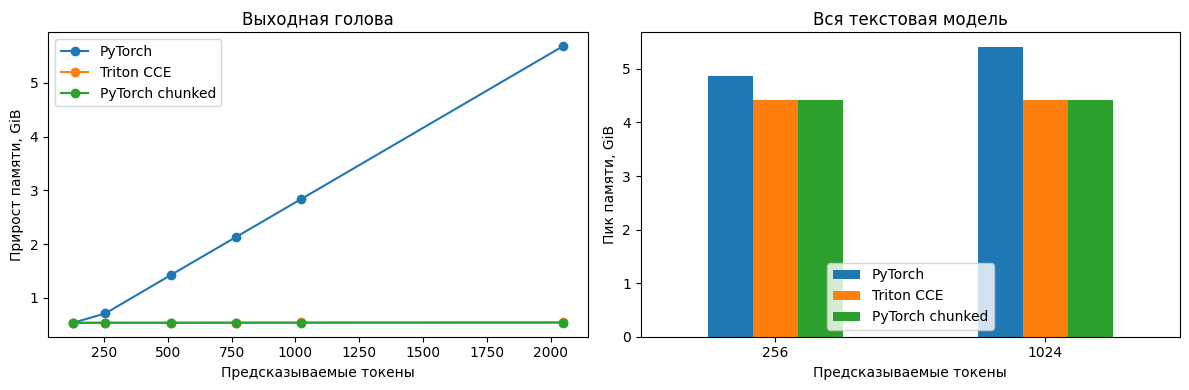

In [16]:
baseline = results[results.method == 'PyTorch'][
    ['experiment', 'tokens', 'peak_GiB', 'extra_GiB']]
comparison = results.merge(baseline, on=['experiment', 'tokens'],
                           suffixes=('', '_PyTorch'))
comparison['extra_saving_%'] = 100 * (1 - comparison.extra_GiB / comparison.extra_GiB_PyTorch)
comparison['peak_saving_%'] = 100 * (1 - comparison.peak_GiB / comparison.peak_GiB_PyTorch)
comparison = comparison[['experiment', 'tokens', 'method', 'peak_GiB', 'extra_GiB',
                         'extra_saving_%', 'peak_saving_%']]
display(comparison.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in methods:
    part = results[(results.experiment == 'head') & (results.method == name)]
    axes[0].plot(part.tokens, part.extra_GiB, marker='o', label=name)
axes[0].set(xlabel='Предсказываемые токены', ylabel='Прирост памяти, GiB',
            title='Выходная голова')
axes[0].legend()

part = results[results.experiment == 'model'].pivot(
    index='tokens', columns='method', values='peak_GiB')
part[list(methods)].plot.bar(ax=axes[1], rot=0)
axes[1].set(xlabel='Предсказываемые токены', ylabel='Пик памяти, GiB',
            title='Вся текстовая модель')
axes[1].legend(title=None)
fig.tight_layout()
plt.savefig('memory_comparison.png', dpi=150)
plt.show()
comparison.to_csv('memory_results.csv', index=False)

# Выводы
 реализация функции потерь CUT YOUR LOSSES
IN LARGE-VOCABULARY LANGUAGE MODELS считает данные небольшими порциями, которые помещаются в SRAM и не хранит сразу большую таблицу логитов. Основную память занимает градиент весов модели его размер не меняется, когда токенов становится больше. С токенами растёт время вычислений, но память не увеличивается.